# Visualize Model Output

Loaded output for J1620+1203 with model ID starred_jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
-0.856067389411658 reduced X^2 of all evaluated imaging data combined (without degrees of freedom subtracted).
reduced chi^2 of data  0 =  0.6720068827799852
reduced chi^2 of data  1 =  0.9051243871609789
reduced chi^2 of data  2 =  0.9588549854892241


/Users/rbrady0110/micromamba/envs/tensorflow/lib/python3.12/site-packages/lenstronomy/Plots/model_band_plot.py:88: RuntimeWarning: divide by zero encountered in log10
  log_model = np.log10(model)
/Users/rbrady0110/micromamba/envs/tensorflow/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a
/Users/rbrady0110/micromamba/envs/tensorflow/lib/python3.12/site-packages/lenstronomy/Plots/model_band_plot.py:218: RuntimeWarning: invalid value encountered in log10
  np.log10(self._data),
/Users/rbrady0110/micromamba/envs/tensorflow/lib/python3.12/site-packages/lenstronomy/Plots/model_band_plot.py:309: RuntimeWarning: divide by zero encountered in log10
  np.log10(self._model),


Text(0.5, 0.91, 'J1620+1203: STARRED Model Visualization')

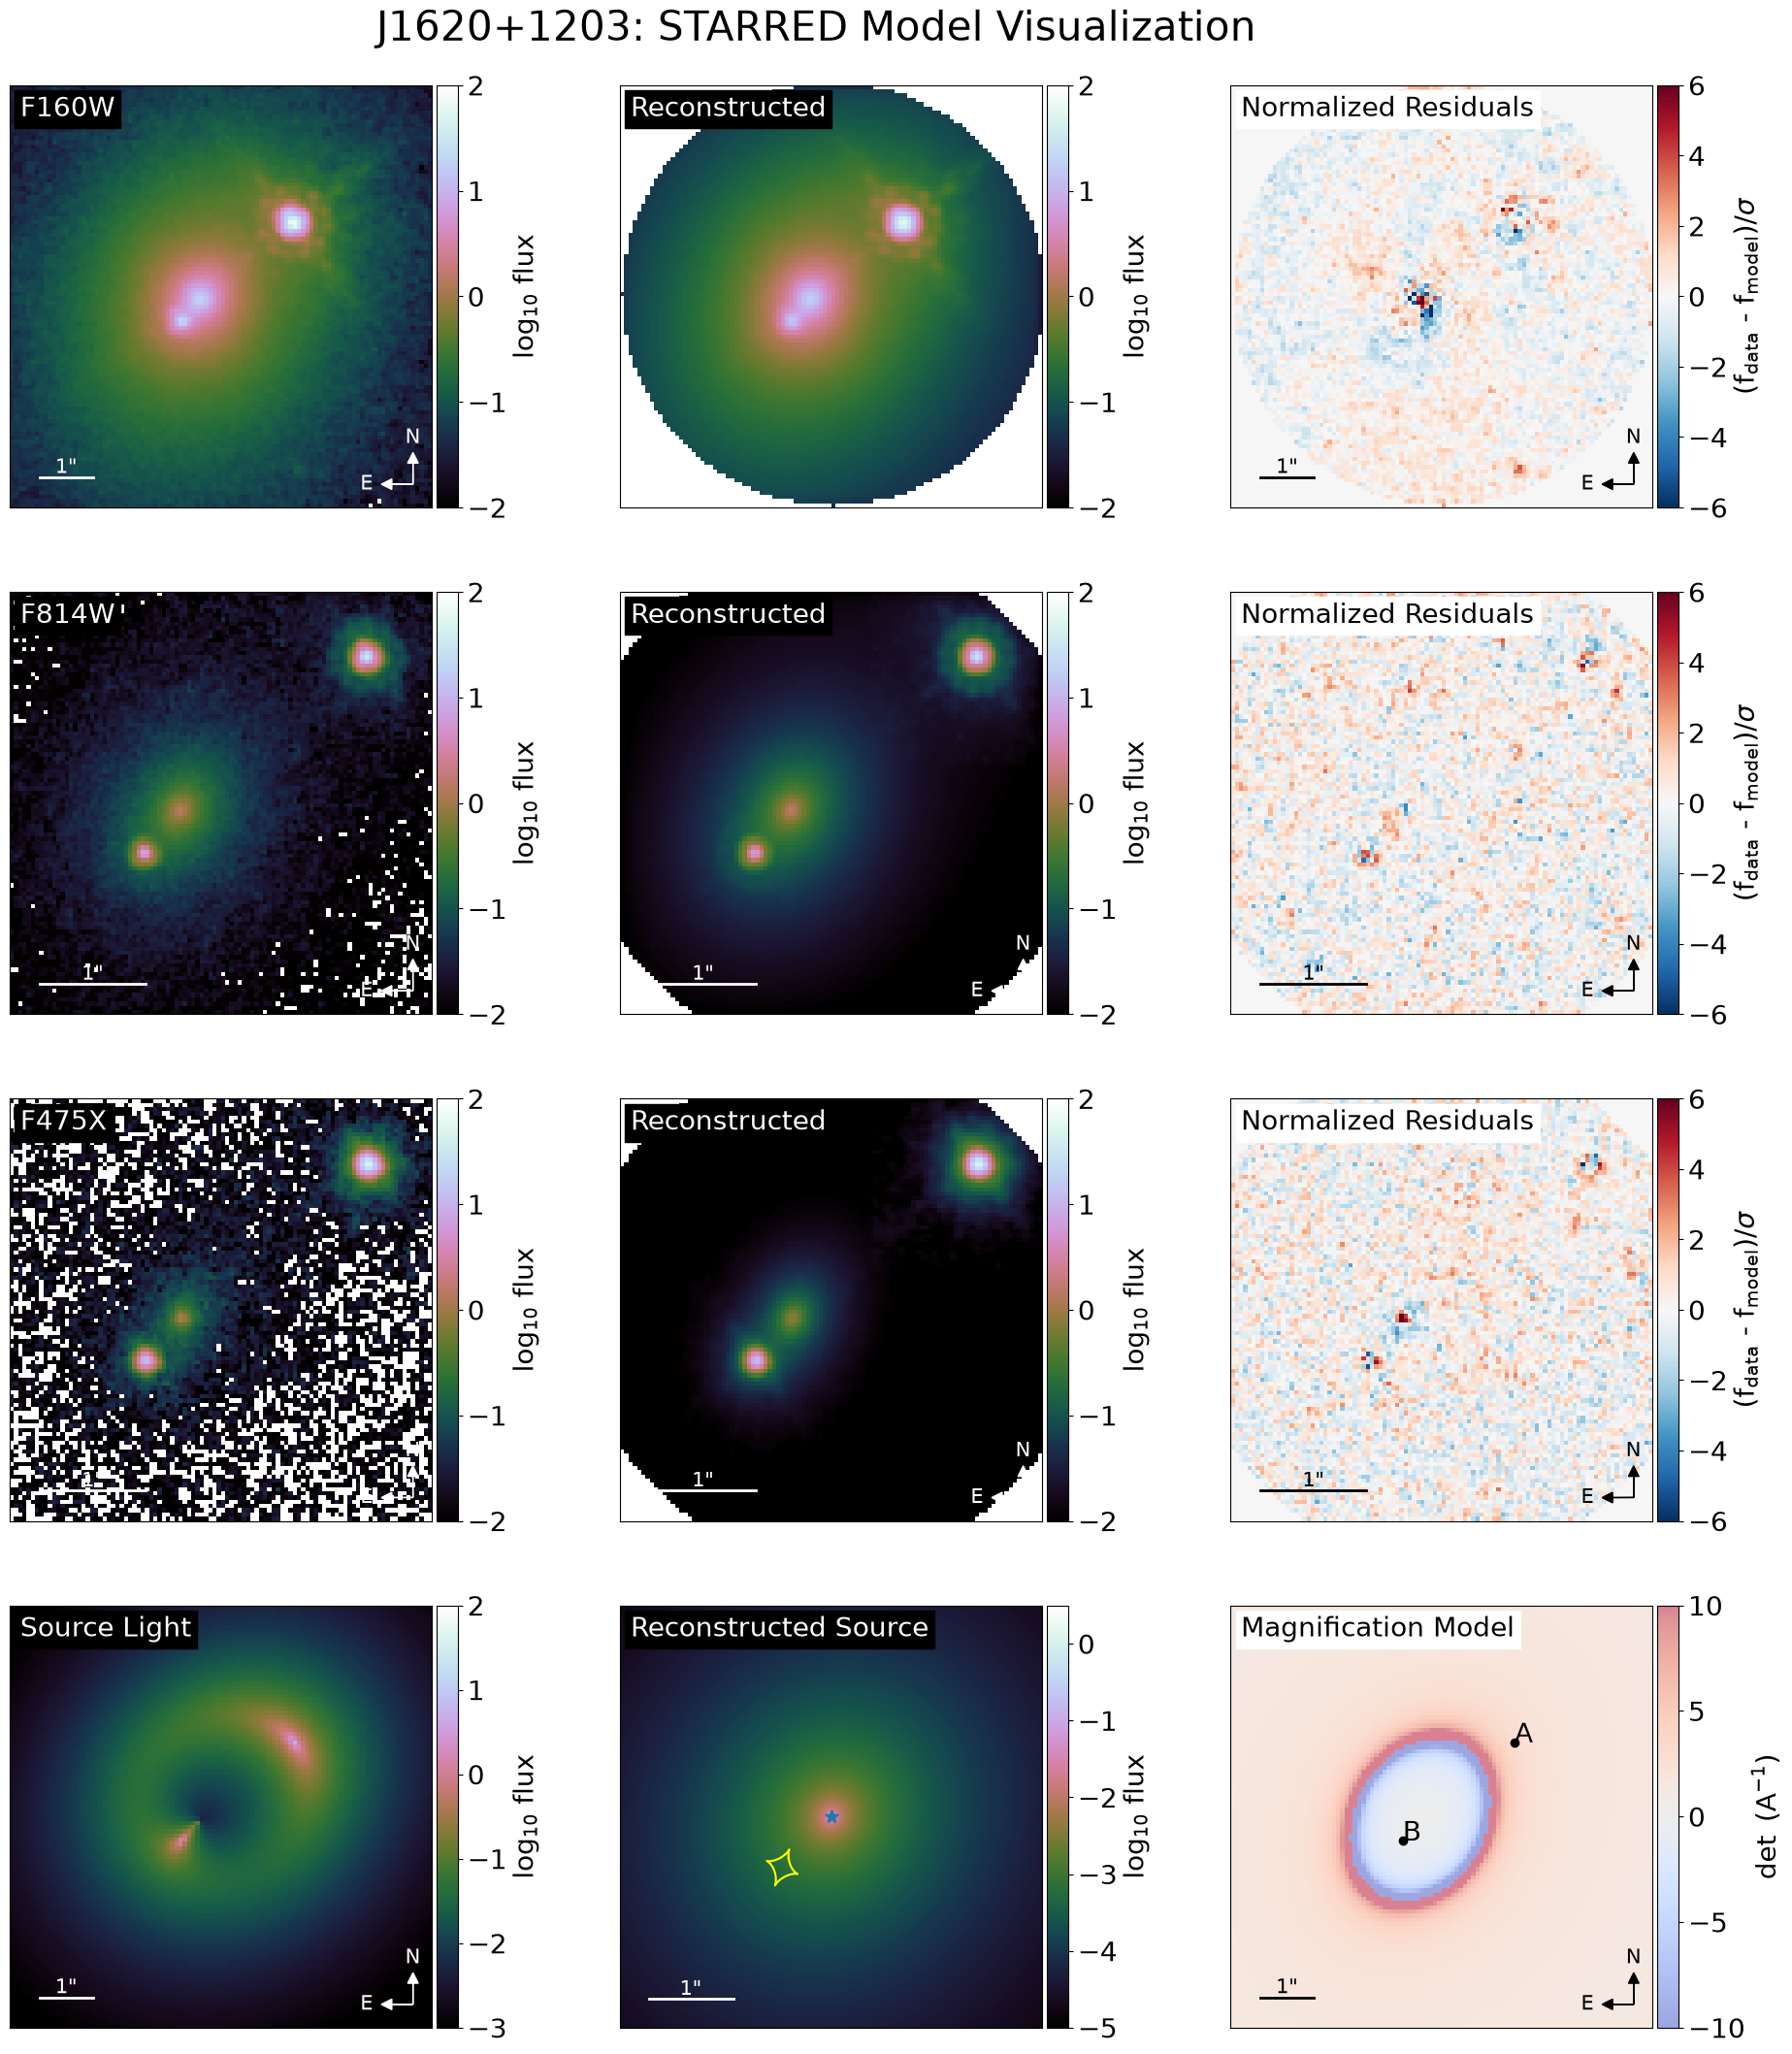

In [3]:
from dolphin.processor import Processor
from dolphin.analysis.output import Output
from dolphin.processor.config import ModelConfig
from lenstronomy.Plots.model_plot import ModelPlot

import matplotlib.pyplot as plt
import numpy as np

name='J1620+1203'
psf_method="starred"
ID=f'{psf_method}_jax'
io_dir=f"{psf_method}_models/"
output = Output(io_dir)

vmax=2
vmin=-2
font_size = 20

output.load_output(name, ID)

kwargs_result = output.kwargs_result
multi_band_list = output._multi_band_list_out
kwargs_data_joint = output.get_kwargs_data_joint(f"{name}")

config = ModelConfig(
            lens_name=name,
            io_directory=io_dir,
            settings=output.model_settings,
        )

mask = config.get_masks()
kwargs_model = config.get_kwargs_model()
constraints = config.get_kwargs_constraints()
likelihood = config.get_kwargs_likelihood()

modelPlot = ModelPlot(multi_band_list, kwargs_model, kwargs_result, image_likelihood_mask_list=mask)

fig, ax = plt.subplots(4, 3, figsize=(23, 26))

axes = ax.flatten()

modelPlot.data_plot(band_index=0, ax=axes[0], vmin=vmin, vmax=vmax, 
                    kwargs_title={"text": "F160W", "font_size": font_size}, font_size=font_size)
modelPlot.model_plot(ax=axes[1], band_index=0, vmin=vmin, vmax=vmax, 
                     kwargs_title={"font_size": font_size}, font_size=font_size)
modelPlot.normalized_residual_plot(ax=axes[2],vmin=-6,vmax=6,band_index=0, cmap='RdBu_r', 
                                   kwargs_title={"font_size": font_size}, font_size=font_size)

modelPlot.data_plot(band_index=1, ax=axes[3], vmin=vmin, vmax=vmax, 
                    kwargs_title={"text": "F814W", "font_size": font_size}, font_size=font_size)
modelPlot.model_plot(ax=axes[4], band_index=1, vmin=vmin, vmax=vmax, 
                     kwargs_title={"font_size": font_size}, font_size=font_size)
modelPlot.normalized_residual_plot(ax=axes[5],vmin=-6,vmax=6,band_index=1, cmap='RdBu_r', 
                                   kwargs_title={"font_size": font_size}, font_size=font_size)

modelPlot.data_plot(band_index=2, ax=axes[6], vmin=vmin, vmax=vmax, 
                    kwargs_title={"text": "F475X", "font_size": font_size}, font_size=font_size)
modelPlot.model_plot(ax=axes[7], band_index=2, vmin=vmin, vmax=vmax, 
                     kwargs_title={"font_size": font_size}, font_size=font_size)
modelPlot.normalized_residual_plot(ax=axes[8],vmin=-6,vmax=6,band_index=2, cmap='RdBu_r', 
                                   kwargs_title={"font_size": font_size}, font_size=font_size)

modelPlot.decomposition_plot(
            ax=axes[9], 
            kwargs_title={"text": "Source Light", "font_size": font_size}, 
            source_add=True, 
            unconvolved=True, 
            vmin=-3.,
            vmax = 2.,
            band_index=0,
            font_size=font_size
                )
            
modelPlot.source_plot(
            ax=axes[10], kwargs_title={"text": "Reconstructed Source", "font_size": font_size}, delta_pix_source=0.01, num_pix=500, 
            vmin = -5., vmax = 0.5, band_index=0, font_size=font_size, kwargs_scale_bar={"scale_size": 1}
            )    

modelPlot.magnification_plot(ax=axes[11], kwargs_title={"text": "Magnification Model", "font_size": font_size}, 
                             cmap='coolwarm', band_index=0, font_size=font_size)

fig.suptitle(f"{name}: STARRED Model Visualization", y=.91, fontsize=30)

#plt.savefig(f"{name}_{psf_method}_three_band_model.png")

# Posterior Comparison

In [4]:
# some helper functions
import numpy as np
import corner
import matplotlib.pyplot as plt
import matplotlib as mpl
from lenstronomy.Util import param_util
from typing import Dict, Tuple, List
from dolphin.analysis.output import Output
import numpy as np

mpl.rcParams["font.family"] = "serif"

# Literature values (Brady et al. 2026)
literature = {
    "theta_E": (1.431, 0.02),
    "q_mass": (0.76, 0.05),
    "phi_mass": (180 - 58.4, 4.2),
    "gamma_ext": (0.041, 0.02),
    "phi_ext": (180 - 33.0, 15.0),
}

def load_chain(output, param_names, name, model_id, walker_ratio, burn_in):
    """
    Extract parameters used in the corner plot.
    """

    chain = output.get_reshaped_emcee_chain(
        name, model_id, walker_ratio, burn_in=burn_in
    )

    num_params = output.num_params_sampled

    if len(param_names) == 0:
        parameter_list = np.arange(num_params)
    else:
        parameter_list = []
        for i in param_names:
            if i in output.params_sampled:
                parameter_list.append(output.params_sampled.index(i))
            else:
                raise ValueError(
                    f"Parameter '{i}' not found. Available parameters: {output.params_sampled}"
                )

    # Flatten walkers x steps for each requested parameter
    raw_samples = {}
    for i in parameter_list:
        param_name = output.params_sampled[i]
        raw_samples[param_name] = chain[:, :, i].flatten()

    return raw_samples

def convert_ellipticity_to_q_phi(e1_samples, e2_samples):
    
    # Convert e1, e2 to phi, q
    phi_mass, q_mass = param_util.ellipticity2phi_q(e1_samples, e2_samples)
    phi_mass = np.degrees(phi_mass) % 180
    phi_mass = (phi_mass) % 180
    
    return phi_mass, q_mass

Loaded output for J1620+1203 with model ID starred_jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for J1620+1203 with model ID starred_jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for J1620+1203 with model ID psfr_jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for J1620+1203 with model ID psfr_jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


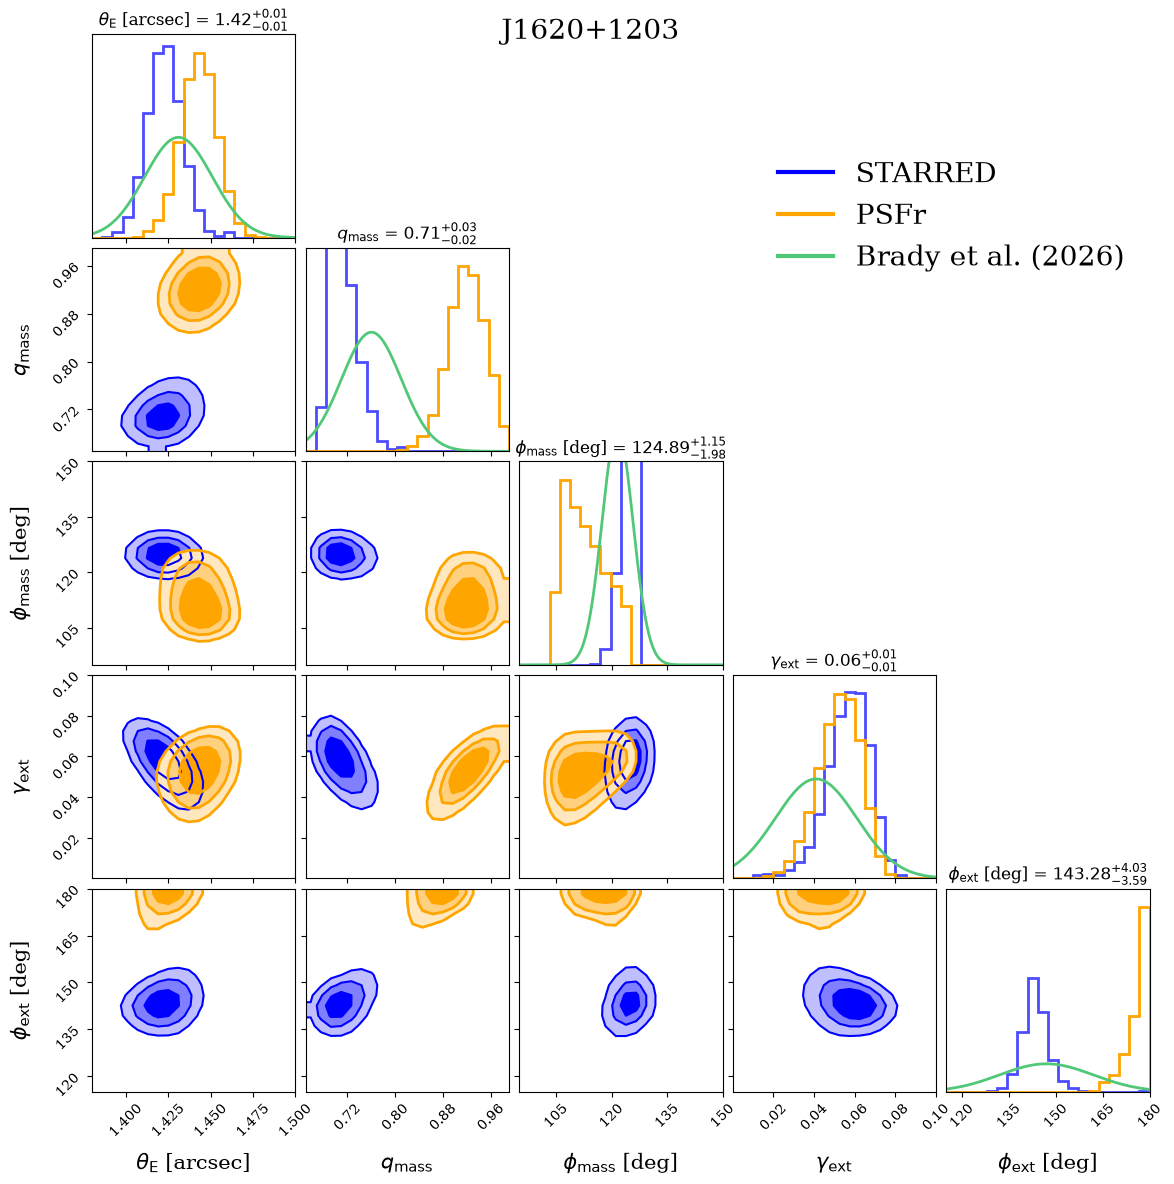

In [5]:
param_names = [
    "theta_E_lens0",
    "e1_lens0",
    "e2_lens0",
    "gamma_ext_lens1",
    "psi_ext_lens1"
]

# Load chains
name = "J1620+1203"
burn_in = 0

output_starred = Output("starred_models")
output_starred.load_output("J1620+1203", "starred_jax")
data_starred_dict = load_chain(output_starred, param_names, "J1620+1203",
                          "starred_jax", 10, burn_in)
psi_ext = np.degrees(data_starred_dict["psi_ext_lens1"]) % 180
psi_ext = psi_ext % 180
phi_mass, q_mass = convert_ellipticity_to_q_phi(data_starred_dict["e1_lens0"], data_starred_dict["e2_lens0"])
data_starred = np.column_stack([
    data_starred_dict["theta_E_lens0"],
    q_mass,
    phi_mass,
    data_starred_dict["gamma_ext_lens1"],
    psi_ext
])

output_psfr = Output("psfr_models")
output_psfr.load_output("J1620+1203", "psfr_jax")
data_psfr_dict = load_chain(output_psfr, param_names, "J1620+1203",
                          "psfr_jax", 10, burn_in)
psi_ext = np.degrees(data_psfr_dict["psi_ext_lens1"]) % 180
psi_ext = psi_ext % 180
phi_mass, q_mass = convert_ellipticity_to_q_phi(data_psfr_dict["e1_lens0"], data_psfr_dict["e2_lens0"])
data_psfr = np.column_stack([
    data_psfr_dict["theta_E_lens0"],
    q_mass,
    phi_mass,
    data_psfr_dict["gamma_ext_lens1"],
    psi_ext
])


# Labels
labels = [
    r"$\theta_{\rm E}$ [arcsec]",
    r"$q_{\rm mass}$",
    r"$\phi_{\rm mass}$ [deg]",
    r"$\gamma_{\rm ext}$",
    r"$\phi_{\rm ext}$ [deg]",
    r"$\Delta \Phi_{\rm AB}$"
]


# X-axis range for plotting
manual_range = {
    "theta_E": (1.38, 1.5),
    "q_mass": (0.65, 0.99),
    "phi_mass": (95, 150),
    "gamma_ext": (0., 0.1),
    "phi_ext": (115, 180),
}

shared_range = []

param_keys = ["theta_E", "q_mass", "phi_mass", "gamma_ext", "phi_ext"]

for i, key in enumerate(param_keys):

    override = manual_range.get(key)

    if override is not None:
        shared_range.append(override)
        continue

    mu, sigma = literature[key]

    # Include +/- 4 sigma for the literature Gaussian
    literature_lo = mu - 4 * sigma
    literature_hi = mu + 4 * sigma

    lo = min(
        data_starred[:, i].min(),
        data_psfr[:, i].min(),
        literature_lo,
    )

    hi = max(
        data_starred[:, i].max(),
        data_psfr[:, i].max(),
        literature_hi,
    )

    pad = 0.01 * (hi - lo)

    shared_range.append((lo - pad, hi + pad))

bins=20
# STARRED
fig = corner.corner(
    data_starred,
    labels=labels,
    color="blue",
    levels=(0.393, 0.675, 0.865),
    smooth=1.0,
    bins=bins,
    range=shared_range,
    fill_contours=True,
    plot_datapoints=False,
    show_titles=True,
    hist_kwargs={
        "linewidth": 2,
        "density": True,
        "alpha": 0.7,
    },
    contour_kwargs={
        "linewidths": 1.5,
    },
    label_kwargs={
        "fontsize": 15,
    },
    title_kwargs={
        "fontsize": 12,
    },
)


# PSFr
corner.corner(
    data_psfr,
    labels=labels,
    color="orange",
    levels=(0.393, 0.675, 0.865),
    smooth=1.0,
    bins=bins,
    range=shared_range,
    fill_contours=True,
    plot_datapoints=False,
    show_titles=False,
    hist_kwargs={
        "linewidth": 2,
        "density": True,
        "alpha": 1.,
    },
    contour_kwargs={
        "linewidths": 2,
    },
    label_kwargs={
        "fontsize": 15,
    },
    title_kwargs={
        "fontsize": 12,
    },
    fig=fig,
)


# Brady et al. Gaussian distributions
literature_order = [
            "theta_E",
            "q_mass",
            "phi_mass",
            "gamma_ext",
            "phi_ext",
]

# Shared plotting ranges
n_params = data_starred.shape[1]
axes = np.array(fig.axes).reshape(
    n_params,
    n_params,
)

for i, key in enumerate(literature_order):

    mu, sigma = literature[key]

    ax = axes[i, i]

    x = np.linspace(
        shared_range[i][0],
        shared_range[i][1],
        500,
    )

    gaussian = (
        np.exp(
            -0.5 * ((x - mu) / sigma) ** 2
        )
        / (sigma * np.sqrt(2 * np.pi))
    )

    ax.plot(
        x,
        gaussian,
        color="#50C878",
        linewidth=2,
    )

handles = [
    plt.Line2D(
        [],
        [],
        color="blue",
        lw=3,
        label="STARRED",
    ),
    plt.Line2D(
        [],
        [],
        color="orange",
        lw=3,
        label="PSFr",
    ),
    plt.Line2D(
        [],
        [],
        color="#50C878",
        lw=3,
        label="Brady et al. (2026)",
    ),
]

for ax in fig.get_axes():
    ax.tick_params(labelsize=10)


fig.axes[0].legend(
    handles=handles,
    fontsize=20,
    frameon=False,
    bbox_to_anchor=(5.2, 0.5),
)


plt.suptitle(
    name,
    fontsize=20,
)

fig.set_size_inches(
    12,
    12,
)

#plt.savefig("J1620_posterior.png")
plt.show()

# Fermat Potentials

In [1]:
import numpy as np
from astropy.cosmology import FlatLambdaCDM
from dolphin.analysis.cosmology import Cosmology

H0 = 70
Om0 = 0.3
cosmology_model = FlatLambdaCDM(H0=H0, Om0=Om0)

psf_method="psfr"
io_directory=f"{psf_method}_models"
lens_name="J1620+1203"
model_id=f"psfr_jax"
z_lens=0.398
z_source=1.158
n_samples=5000

cosmology = Cosmology(io_directory=io_directory,
                      lens_name=lens_name,
                      model_id=model_id,
                      z_lens=z_lens,
                      z_source=z_source,
                      cosmology_model=cosmology_model,
                      walker_ratio=10,
                      burn_in=0,
                      n_samples=n_samples,
                      rng_seed=32
                    )

samples_fermat_psfr = cosmology.fermat_potential()

psf_method="starred"
io_directory=f"{psf_method}_models"
lens_name="J1620+1203"
model_id=f"starred_jax"

cosmology = Cosmology(io_directory=io_directory,
                      lens_name=lens_name,
                      model_id=model_id,
                      z_lens=z_lens,
                      z_source=z_source,
                      cosmology_model=cosmology_model,
                      walker_ratio=10,
                      burn_in=0,
                      n_samples=n_samples,
                      rng_seed=32
                    )

samples_fermat_starred = cosmology.fermat_potential()

Loaded output for J1620+1203 with model ID psfr_jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for J1620+1203 with model ID psfr_jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for J1620+1203 with model ID starred_jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for J1620+1203 with model ID starred_jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


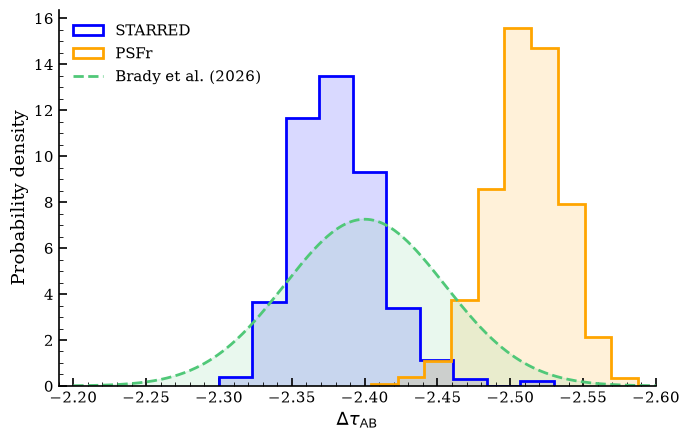

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams["font.family"] = "serif"

literature_order = {"delta_fermat12": (-2.4, 0.055)}

fig, ax = plt.subplots(figsize=(7, 4.5))

# Histograms

ax.hist(
    samples_fermat_starred,
    #bins=bins,
    density=True,
    histtype="stepfilled",
    alpha=0.15,
    color="blue",
    zorder=1,
)
ax.hist(
    samples_fermat_starred,
    #bins=bins,
    density=True,
    histtype="step",
    linewidth=2.0,
    label="STARRED",
    color="blue",
    zorder=2,
)

ax.hist(
    samples_fermat_psfr,
    #bins=bins,
    density=True,
    histtype="stepfilled",
    alpha=0.15,
    color="orange",
    zorder=1,
)
ax.hist(
    samples_fermat_psfr,
    #bins=bins,
    density=True,
    histtype="step",
    linewidth=2.0,
    label="PSFr",
    color="orange",
    zorder=2,
)

# Literature result
for key, (mu, sigma) in literature_order.items():

    x = np.linspace(-2.2, -2.7, 500)

    gaussian = (
        np.exp(-0.5 * ((x - mu) / sigma) ** 2)
        / (sigma * np.sqrt(2 * np.pi))
    )

    # Gaussian distribution
    ax.plot(
        x,
        gaussian,
        linewidth=2,
        linestyle="--",
        label="Brady et al. (2026)",
        color="#50C878"
    )

    # 1-sigma region
    ax.fill_between(
        x,
        0,
        gaussian,
        alpha=0.12,
        color="#50C878"
    )

# Formatting
ax.set_xlabel(r"$\Delta \tau_{\mathrm{AB}}$", fontsize=13)
ax.set_ylabel("Probability density", fontsize=13)

ax.set_xlim(-2.19, -2.6)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=6,
    width=1.2,
    labelsize=11,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3,
)

ax.minorticks_on()

# Clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)

ax.legend(
    frameon=False,
    fontsize=11,
    loc="upper left",
)

fig.tight_layout()

#plt.savefig("J1620+1203_fermat_compare.png")
plt.show()